In [1]:
import pandas as pd
import numpy as np
import shap
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LassoCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import r2_score
import joblib

# Modeling

In [2]:
df = pd.read_csv('../data/03_processed/cleaned_insurance.csv')
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1332,50,male,30.970,3,no,northwest,10600.54830
1333,18,female,31.920,0,no,northeast,2205.98080
1334,18,female,36.850,0,no,southeast,1629.83350
1335,21,female,25.800,0,no,southwest,2007.94500


In [3]:
# Feature Engineering
df_model = pd.get_dummies(
    df.assign(
        sex=lambda x: x["sex"].map({"female": 0, "male": 1}),
        children=lambda x: (x["children"] > 0).astype(int),
        smoker=lambda x: x["smoker"].map({"no": 0, "yes": 1})
    ),
    columns=["region"],
    drop_first=True,
    dtype=int
)

df_model

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,16884.92400,0,0,1
1,18,1,33.770,1,0,1725.55230,0,1,0
2,28,1,33.000,1,0,4449.46200,0,1,0
3,33,1,22.705,0,0,21984.47061,1,0,0
4,32,1,28.880,0,0,3866.85520,1,0,0
...,...,...,...,...,...,...,...,...,...
1332,50,1,30.970,1,0,10600.54830,1,0,0
1333,18,0,31.920,0,0,2205.98080,0,0,0
1334,18,0,36.850,0,0,1629.83350,0,1,0
1335,21,0,25.800,0,0,2007.94500,0,0,1


In [4]:
# Linear Regression
X = df_model.drop(columns=["charges"])
y = df_model["charges"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred = linear_model.predict(X_test)

print("R²:", r2_score(y_test, y_pred))

R²: 0.8072773483393474


In [5]:
# Polynomial Regression with Lasso Regularization
X = df_model.drop(columns="charges")
y = df_model["charges"]

poly = PolynomialFeatures(degree=2, interaction_only=False, include_bias=False)
X_poly = pd.DataFrame(
    poly.fit_transform(X),
    columns=poly.get_feature_names_out(X.columns),
    index=X.index
)
binary_cols = ["sex", "children", "smoker"] + [col for col in X.columns if col.startswith("region_")]

X_poly = X_poly.drop(
    columns=[f"{col}^2" for col in binary_cols]
)
feature_names = X_poly.columns

X_train, X_test, y_train, y_test = train_test_split(X_poly, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lasso = LassoCV(cv=10, max_iter=10000)
lasso.fit(X_train_scaled, y_train)

print(f"Lasso R²: {lasso.score(X_test_scaled, y_test):.4f}")

Lasso R²: 0.8863


In [6]:
# Feature Importance
(
    pd.Series(lasso.coef_, index=feature_names)
    .to_frame('coef')
    .assign(abs_coef=lambda x: x['coef'].abs())
    .sort_values('abs_coef', ascending=False)
    .drop(columns='abs_coef')
    .round()
)

,coef
bmi smoker,17911.0
smoker,-7722.0
age^2,4143.0
bmi,1710.0
bmi^2,-1587.0
bmi region_southeast,-1514.0
age region_southeast,925.0
age,-824.0
region_southwest,-774.0
children,604.0


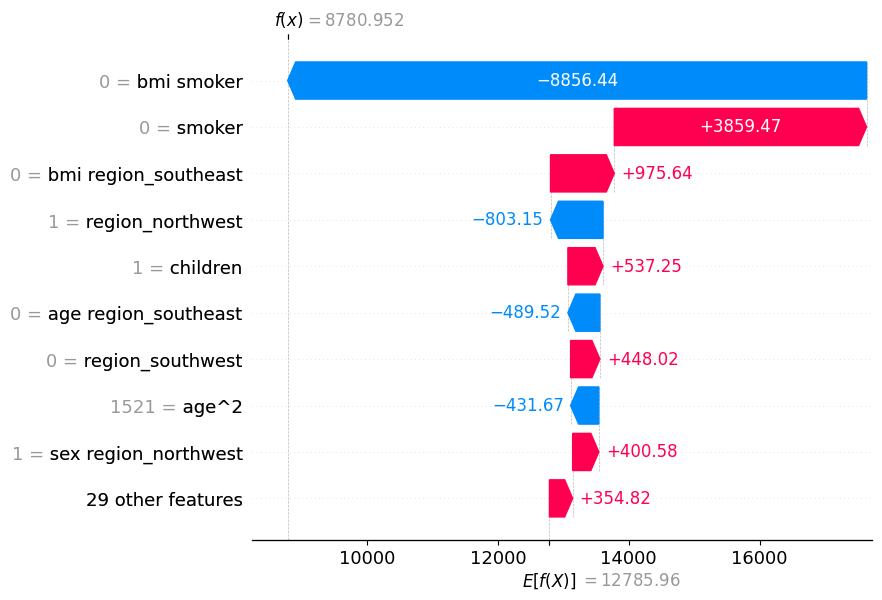

Estimated Insurance Charge: $8,780.95


In [7]:
# Interpretability
background = pd.DataFrame(
    X_train_scaled,
    columns=feature_names
)

explainer = shap.LinearExplainer(
    lasso,
    shap.maskers.Independent(background)
)

def predict_insurance_cost(
    age, sex, bmi, children, smoker,
    region_northwest=0,
    region_southeast=0,
    region_southwest=0
):
    person = pd.DataFrame([{
        "age": age,
        "sex": sex,
        "bmi": bmi,
        "children": children,
        "smoker": smoker,
        "region_northwest": region_northwest,
        "region_southeast": region_southeast,
        "region_southwest": region_southwest
    }])[X.columns]

    person_poly = pd.DataFrame(
        poly.transform(person),
        columns=poly.get_feature_names_out(X.columns)
    )[list(feature_names)]

    person_scaled = scaler.transform(person_poly)

    prediction = lasso.predict(person_scaled)

    person_scaled_df = pd.DataFrame(
        person_scaled,
        columns=feature_names
    )

    shap_values = explainer(person_scaled_df)
    shap_values.data = person_poly.to_numpy()

    shap.plots.waterfall(shap_values[0], max_display=10)

    return f"Estimated Insurance Charge: ${prediction[0]:,.2f}"

print(predict_insurance_cost(
    age=39,
    sex=1,
    bmi=30.4,
    children=1,
    smoker=0,
    region_northwest=1
))

In [8]:
# Save full trained model
X = df_model.drop(columns="charges")
y = df_model["charges"]

poly = PolynomialFeatures(
    degree=2,
    interaction_only=False,
    include_bias=False
)

X_poly = pd.DataFrame(
    poly.fit_transform(X),
    columns=poly.get_feature_names_out(X.columns),
    index=X.index
)

binary_cols = ["sex", "smoker"] + [
    col for col in X.columns if col.startswith("region_")
]

X_poly = X_poly.drop(
    columns=[f"{col}^2" for col in binary_cols]
)

feature_names = X_poly.columns.tolist()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_poly)

lasso = LassoCV(cv=10, max_iter=10000)
lasso.fit(X_scaled, y)

print(f"Full Dataset R²: {lasso.score(X_scaled, y):.4f}")

joblib.dump({
    "model": lasso,
    "scaler": scaler,
    "poly": poly,
    "feature_names": feature_names,
    "original_columns": X.columns.tolist(),
    "binary_cols": binary_cols
}, '../data/03_processed/lasso_polynomial_model.pkl')

print("Model saved successfully!")


Full Dataset R²: 0.8459
Model saved successfully!


# Scenarios

In [9]:
# Actual Scenario
y_pred = lasso.predict(X_scaled)

predictions_df = df_model.copy()
predictions_df["predicted_charges"] = y_pred

avg_bmi = predictions_df["bmi"].mean()
smoker_pct = predictions_df["smoker"].mean() * 100
total_predicted = predictions_df["predicted_charges"].sum()


print(f"Average BMI: {avg_bmi:.2f}")
print(f"Smokers: {smoker_pct/100:.2%}")
print(f"Total Predicted Charges: ${total_predicted:,.2f}")

Average BMI: 30.66
Smokers: 20.49%
Total Predicted Charges: $17,754,185.43


In [10]:
# Smoker Scenarios
np.random.seed(42)

scenarios = {
    "Best Case": 0.25,
    "Good Case": 0.17,
    "Average Case": 0.1
}

results = []

smoker_indices = np.random.permutation(
    df_model.index[df_model["smoker"] == 1]
)

for scenario, reduction in scenarios.items():

    df_scenario = df_model.copy()
    
    n_change = round(len(smoker_indices) * reduction)

    df_scenario.loc[smoker_indices[:n_change], "smoker"] = 0

    X_scenario = df_scenario[X.columns]

    X_scenario_poly = pd.DataFrame(
        poly.transform(X_scenario),
        columns=poly.get_feature_names_out(X.columns),
        index=X_scenario.index
    )[feature_names]

    X_scenario_scaled = scaler.transform(X_scenario_poly)
    df_scenario["predicted_charges"] = lasso.predict(X_scenario_scaled)

    results.append({
        "Scenario": scenario,
        "Smokers (%)": df_scenario["smoker"].mean() * 100,
        "Total Predicted Charges": df_scenario["predicted_charges"].sum()
    })

df_scenarios = pd.DataFrame(results)

display(df_scenarios.style.format({
    "Smokers (%)": "{:.2f}%",
    "Total Predicted Charges": "${:,.2f}"
}))


,Scenario,Smokers (%),Total Predicted Charges
0,Best Case,15.41%,"$16,057,445.64"
1,Good Case,16.98%,"$16,540,025.57"
2,Average Case,18.47%,"$17,124,969.43"


In [13]:
# BMI Scenarios
scenarios = {
    "Best Case": 0.10,
    "Good Case": 0.07,
    "Average Case": 0.03
}

results = []

for scenario, reduction in scenarios.items():

    df_scenario = df_model.copy()

    df_scenario["bmi"] = df_scenario["bmi"] * (1 - reduction)

    X_scenario = df_scenario[X.columns]

    X_scenario_poly = pd.DataFrame(
        poly.transform(X_scenario),
        columns=poly.get_feature_names_out(X.columns),
        index=X_scenario.index
    )[feature_names]

    X_scenario_scaled = scaler.transform(X_scenario_poly)
    df_scenario["predicted_charges"] = lasso.predict(X_scenario_scaled)

    results.append({
        "Scenario": scenario,
        "Average BMI": df_scenario["bmi"].mean(),
        "Total Predicted Charges": df_scenario["predicted_charges"].sum()
    })

df_bmi_scenarios = pd.DataFrame(results)

display(df_bmi_scenarios.style.format({
    "Average BMI": "{:.2f}",
    "Total Predicted Charges": "${:,.2f}"
}))


,Scenario,Average BMI,Total Predicted Charges
0,Best Case,27.60,"$16,423,917.26"
1,Good Case,28.52,"$16,829,733.99"
2,Average Case,29.74,"$17,361,841.25"
